In [1]:
import sys
from pathlib import Path

package_root = str(Path.cwd().parent)
if package_root not in sys.path:
    sys.path.append(package_root)

In [2]:
import pandas as pd 
from typing import Dict, List, Tuple
from pathlib import Path
from scipy.stats import skew, kurtosis
from package import training_and_evaluation
from collections.abc import Iterable
import matplotlib.pyplot as plt
import seaborn as sns
import os 
import time
import re
import numpy as np
from copy import deepcopy
from datetime import datetime




In [3]:
DATASET_FOLDER = "../../../dataset/processed-data"
DEVICE_MAPPING_FOLDER = DATASET_FOLDER + "/device-mapping"
INPUT_FOLDER = DATASET_FOLDER + "/input-data"
DATASET1 = "dataset1"
DATASET2 = "dataset2"

In [4]:
MAPPING_LIST_1 = f"{DEVICE_MAPPING_FOLDER}/{DATASET1}/list_of_devices_processed.csv"
MAPPING_LIST_2 = f"{DEVICE_MAPPING_FOLDER}/{DATASET2}/list_of_devices_processed.csv"
INPUT_1 = f"{INPUT_FOLDER}/{DATASET1}"
INPUT_2 = f"{INPUT_FOLDER}/{DATASET2}"

In [19]:
csv_files_1 = [f"{INPUT_1}/{f.name}" for f in sorted(Path(INPUT_1).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_1:
    print(file)

../../../dataset/processed-data/input-data/dataset1/16-09-23.csv
../../../dataset/processed-data/input-data/dataset1/16-09-24.csv
../../../dataset/processed-data/input-data/dataset1/16-09-25.csv
../../../dataset/processed-data/input-data/dataset1/16-09-26.csv
../../../dataset/processed-data/input-data/dataset1/16-09-27.csv
../../../dataset/processed-data/input-data/dataset1/16-09-28.csv
../../../dataset/processed-data/input-data/dataset1/16-09-29.csv
../../../dataset/processed-data/input-data/dataset1/16-09-30.csv
../../../dataset/processed-data/input-data/dataset1/16-10-01.csv
../../../dataset/processed-data/input-data/dataset1/16-10-02.csv
../../../dataset/processed-data/input-data/dataset1/16-10-03.csv
../../../dataset/processed-data/input-data/dataset1/16-10-04.csv
../../../dataset/processed-data/input-data/dataset1/16-10-05.csv
../../../dataset/processed-data/input-data/dataset1/16-10-06.csv
../../../dataset/processed-data/input-data/dataset1/16-10-07.csv
../../../dataset/processe

In [20]:
device_mapping_1 = pd.read_csv(MAPPING_LIST_1)
device_dict_1 = (
    device_mapping_1
    .set_index("mac_address")
    .drop(columns=["mac_address"], errors="ignore")
    .to_dict(orient="index")
)
device_dict_1

{'d0:52:a8:00:67:5e': {'device_name': 'Smart Things',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'hub',
  'vendor': 'Samsung SmartThings'},
 '44:65:0d:56:cc:d3': {'device_name': 'Amazon Echo',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'smart speaker',
  'vendor': 'Amazon'},
 '70:ee:50:18:34:43': {'device_name': 'Netatmo Welcome',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Netatmo'},
 'f4:f2:6d:93:51:f1': {'device_name': 'TP-Link Day Night Cloud camera',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'TP-Link'},
 '00:16:6c:ab:6b:88': {'device_name': 'Samsung SmartCam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Samsung'},
 '30:8c:fb:2f:e4:b2': {'device_name': 'Dropcam',
  'ip_address': nan,
  'is_iot_device': 1,
  'device_type': 'camera',
  'vendor': 'Dropcam'},
 '00:62:6e:51:27:2e': {'device_name': 'Insteon Camera',
  'ip_address': nan,
 

# Feature Set 1 - Packet Count and Total Size
- For this experiment, I will be testing only feature `packet count`, and `total size`
- We'll experiment different window size
- We'll be using fixed WINDOW size for this experiment

In [21]:
def calculate_features(file_paths: Iterable[str], window: int) -> Tuple[pd.DataFrame, float]:
    columns = ["frame.time_epoch", "frame.len", "eth.src"]
    all_features = []

    startTime = time.perf_counter()
    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category"
            },
        )
        start = df["frame.time_epoch"].min()

        df["window"] = (
            (df["frame.time_epoch"] - start) // window
        ).astype("int32")

        grouped = df.groupby(
            ["window", "eth.src"],
            sort=False,
            observed=True,
        )["frame.len"]

        basic_features = grouped.agg(
            packet_count="size",
            total_bytes="sum",
        ).reset_index()
        all_features.append(basic_features)
    endTime = time.perf_counter()

    return pd.concat(all_features, ignore_index=True), endTime - startTime


In [22]:
def label_features(features: pd.DataFrame, device_mapping: Dict[str, Dict[str, str]]) -> pd.DataFrame:
    # Check if eth.src is in device_mapping, and get label is_iot_device, device_type, and vendor
    features["is_iot_device"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("is_iot_device", 0)
    )
    features["device_type"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("device_type", "unknown")
    )
    features["vendor"] = features["eth.src"].apply(
        lambda x: device_mapping.get(x, {}).get("vendor", "unknown")
    )
    return features
    

In [9]:
minWindow, maxWindow = 1, 300

In [10]:
metrics = {}
feature_calculate_metric = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(minWindow, maxWindow + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features(csv_files_1, window)
    feature_calculate_metric[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    metrics[window] = experiment_results
    print(f"------------------------------------------")


------------WINDOW: 1-------------
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=SMOTE, scaler=StandardScaler
------------------------------------------
------------WINDOW: 2-------------
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, s

In [ ]:
metric_copy = deepcopy(metrics)
combined_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"combined_results_{timestamp}.csv"

combined_df.to_csv(filename, index=False)

## Performance Plotting

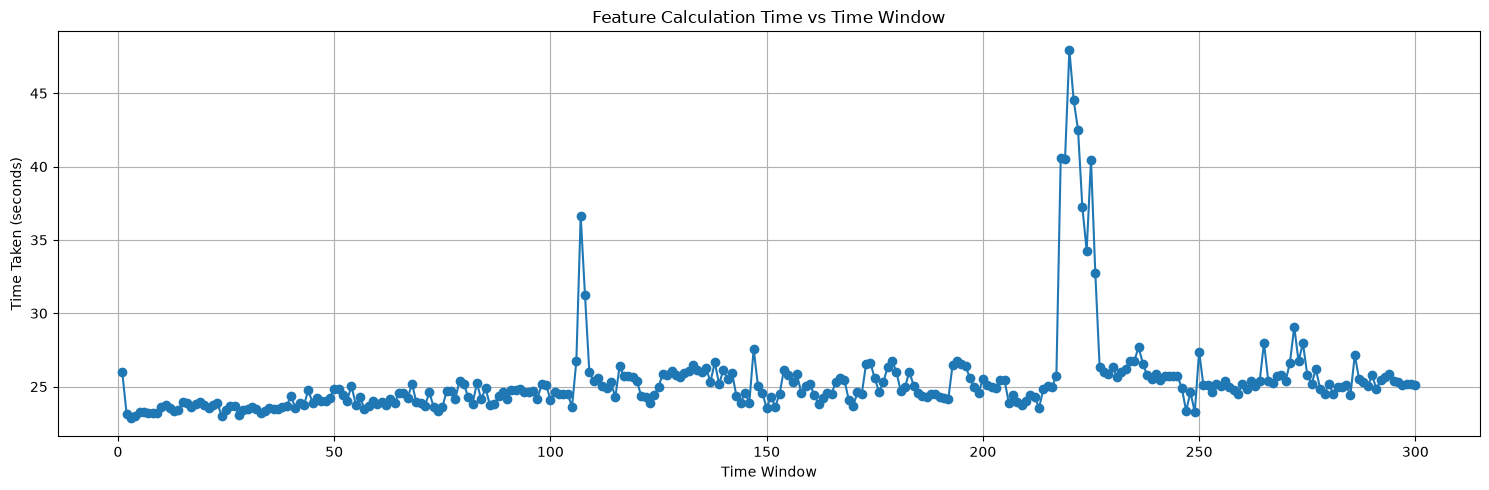

In [ ]:
x = sorted(feature_calculate_metric.keys())
y = [feature_calculate_metric[k] for k in x]

plt.figure(figsize=(15, 5))
plt.plot(x, y, marker="o")
plt.title("Feature Calculation Time vs Time Window")
plt.xlabel("Time Window")
plt.ylabel("Time Taken (seconds)")
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
def plot_results(
    combined_results: pd.DataFrame,
    output_dir: str = "result_plots",
) -> None:
    """
    For every (model, sample_method) pair, generate:
      1. Average accuracy by window, with min/max error bars
      2. Average train time by window, with min/max error bars
    """
    required_columns = {
        "model",
        "sample_method",
        "window",
        "accuracy",
        "train_time",
    }

    missing = required_columns - set(combined_results.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = Path(f"{output_dir}-{timestamp}")
    output_path.mkdir(parents=True, exist_ok=True)

    # Ensure numeric columns are interpreted correctly.
    df = combined_results.copy()
    df["window"] = pd.to_numeric(df["window"], errors="coerce")
    df["accuracy"] = pd.to_numeric(df["accuracy"], errors="coerce")
    df["train_time"] = pd.to_numeric(df["train_time"], errors="coerce")

    df = df.dropna(
        subset=["model", "sample_method", "window", "accuracy", "train_time"]
    )

    grouped = (
        df.groupby(
            ["model", "sample_method", "window"],
            observed=True,
            sort=True,
        )
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_min=("accuracy", "min"),
            accuracy_max=("accuracy", "max"),
            train_time_mean=("train_time", "mean"),
            train_time_min=("train_time", "min"),
            train_time_max=("train_time", "max"),
        )
        .reset_index()
    )

    for (model, sample_method), pair_df in grouped.groupby(
        ["model", "sample_method"],
        observed=True,
        sort=False,
    ):
        pair_df = pair_df.sort_values("window")

        safe_name = re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            f"{model}_{sample_method}",
        )

        # -------------------------
        # Accuracy plot
        # -------------------------
        mean = pair_df["accuracy_mean"]

        plt.figure(figsize=(16, 5))

        plt.errorbar(
            pair_df["window"],
            mean,
            yerr=[
                mean - pair_df["accuracy_min"],
                pair_df["accuracy_max"] - mean,
            ],
            marker="o",
            markersize=4,
            linewidth=1.5,
            capsize=4,
            label="Mean with min/max",
        )

        plt.title(f"Accuracy vs Window\n{model} — {sample_method}")
        plt.xlabel("Window")
        plt.ylabel("Accuracy")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_accuracy.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

        # -------------------------
        # Training-time plot
        # -------------------------
        mean = pair_df["train_time_mean"]

        plt.figure(figsize=(16, 5))

        plt.errorbar(
            pair_df["window"],
            mean,
            yerr=[
                mean - pair_df["train_time_min"],
                pair_df["train_time_max"] - mean,
            ],
            marker="o",
            markersize=4,
            linewidth=1.5,
            capsize=4,
            label="Mean with min/max",
        )

        plt.title(f"Training Time vs Window\n{model} — {sample_method}")
        plt.xlabel("Window")
        plt.ylabel("Training Time (seconds)")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_train_time.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()
        plt.close()

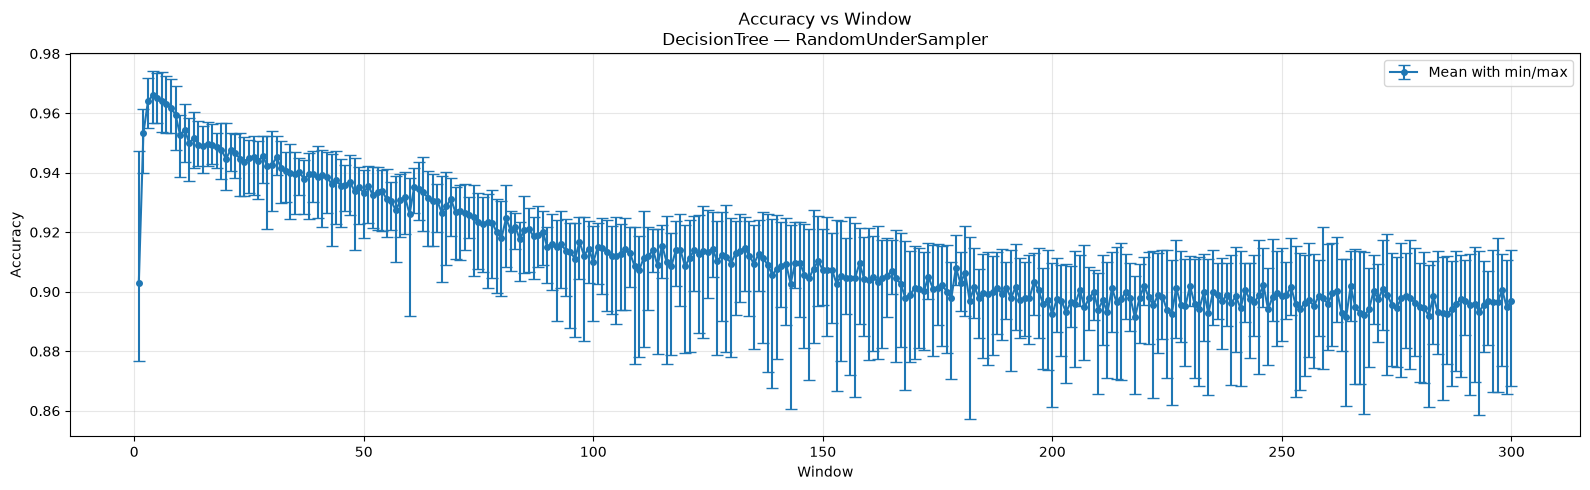

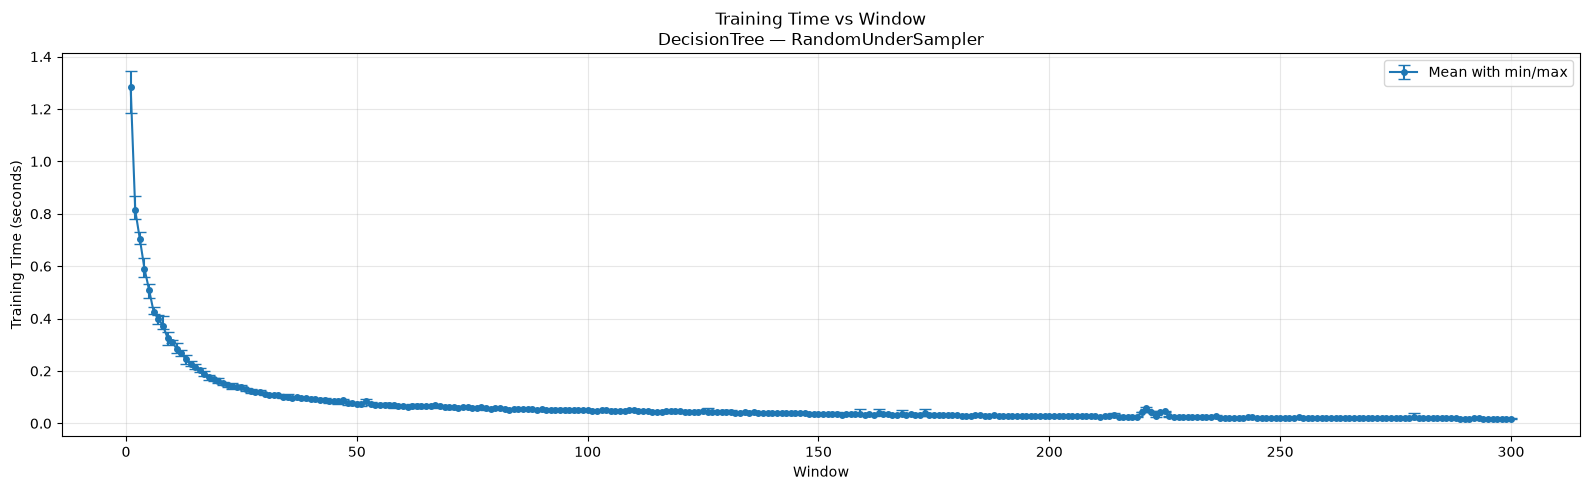

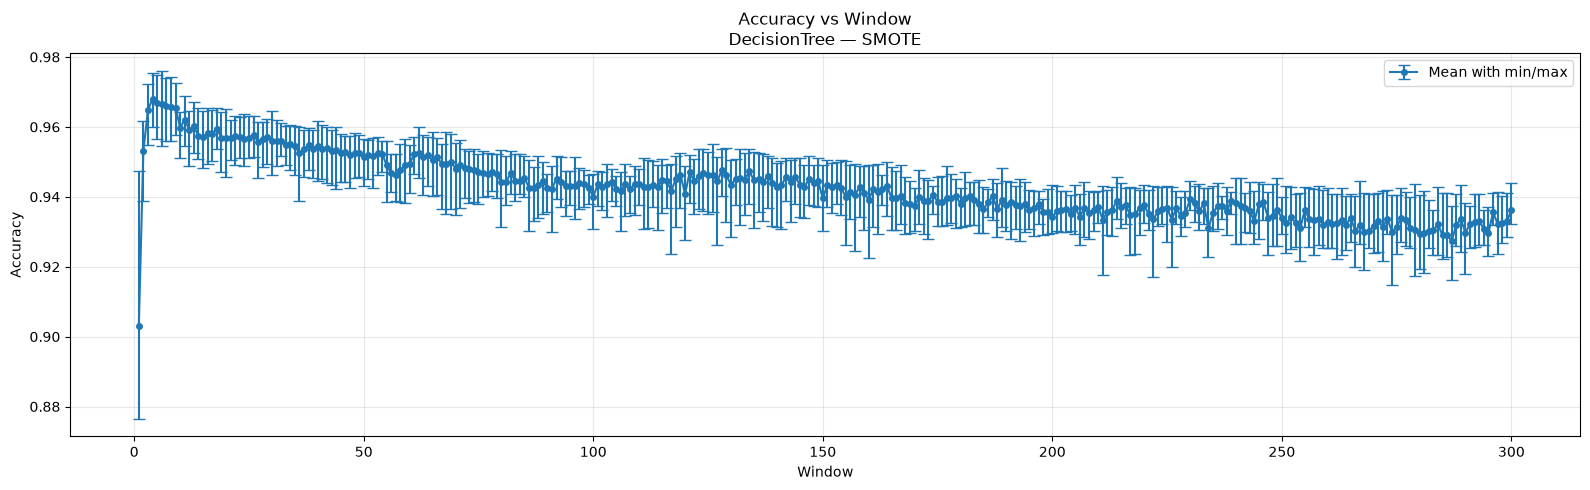

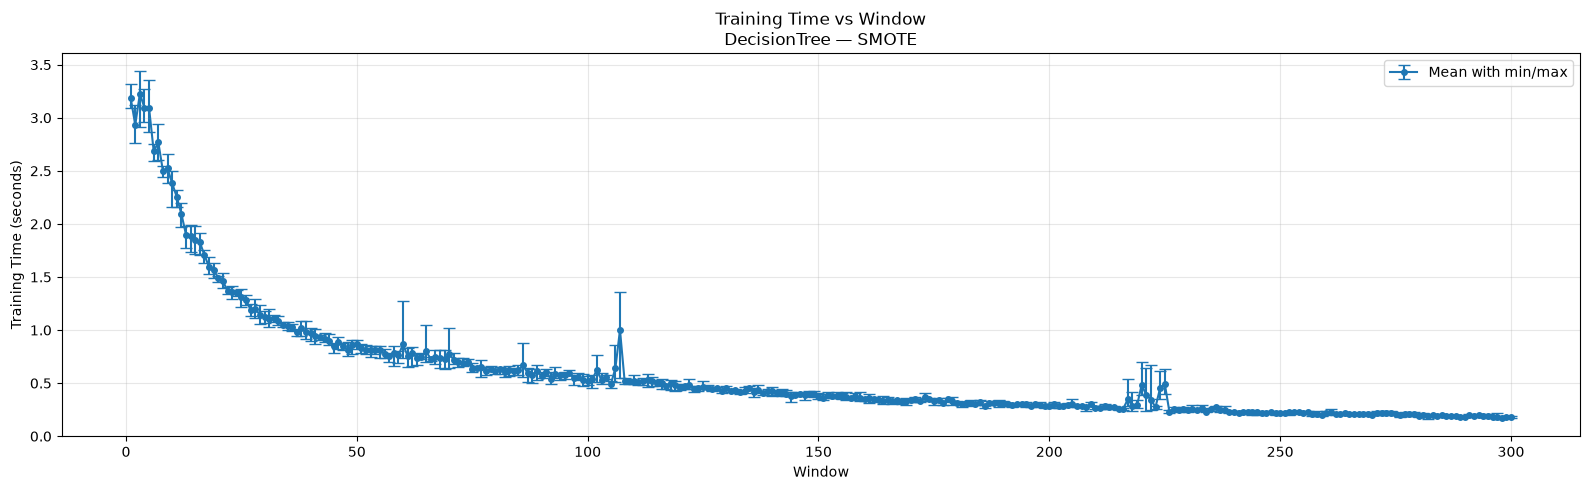

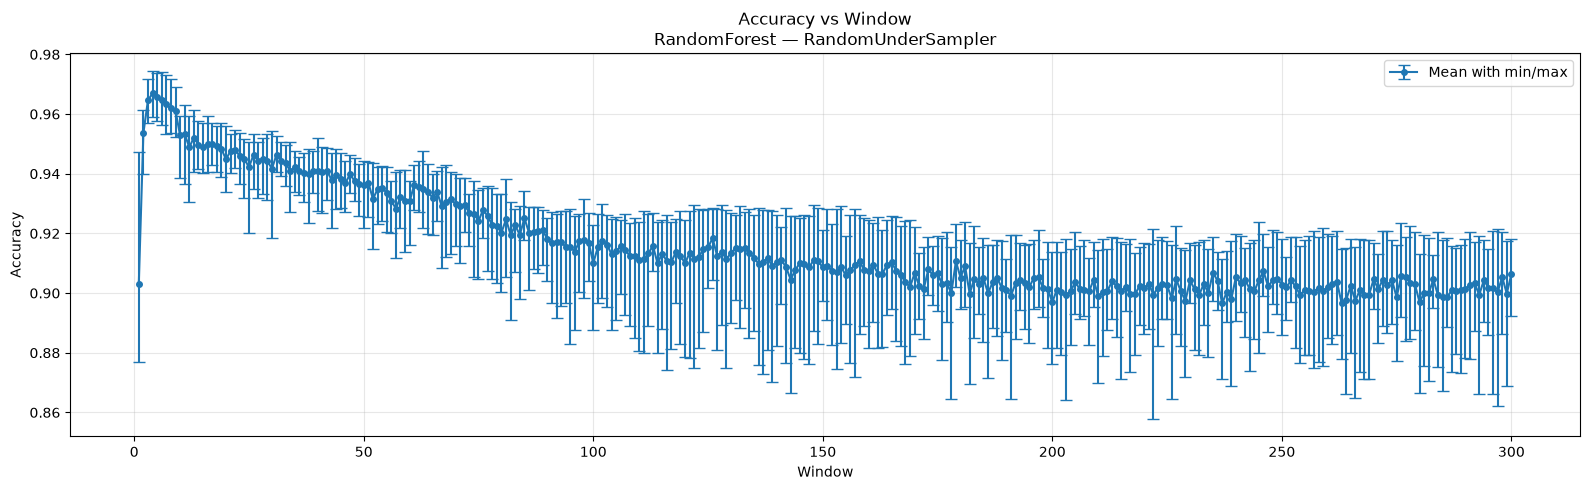

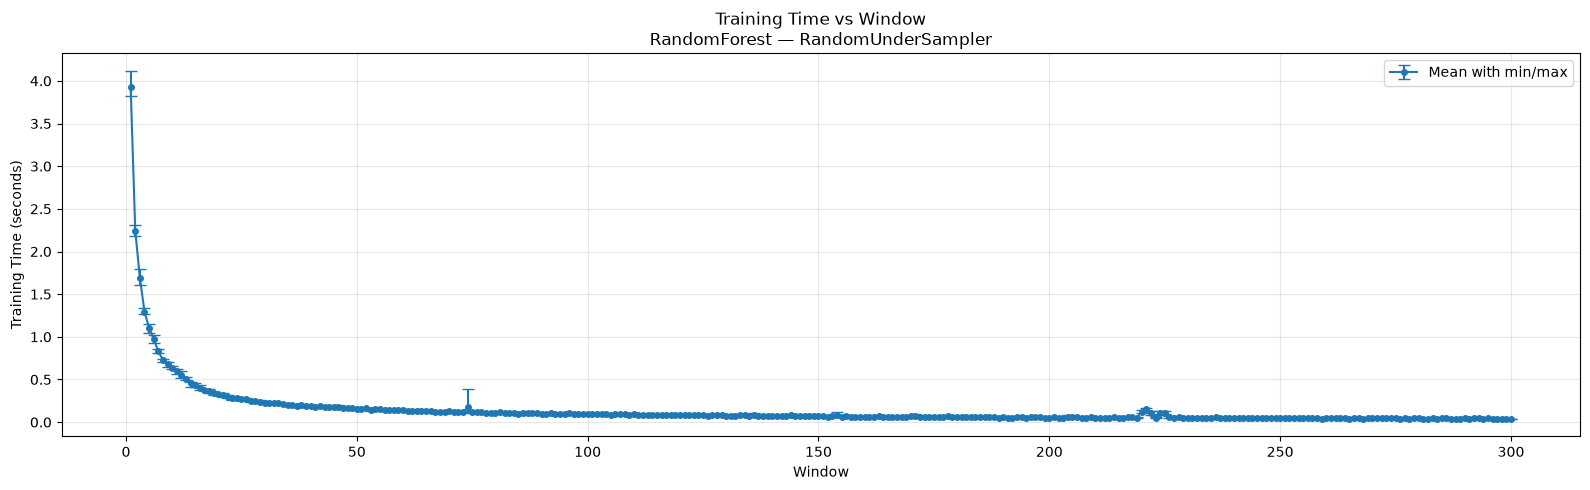

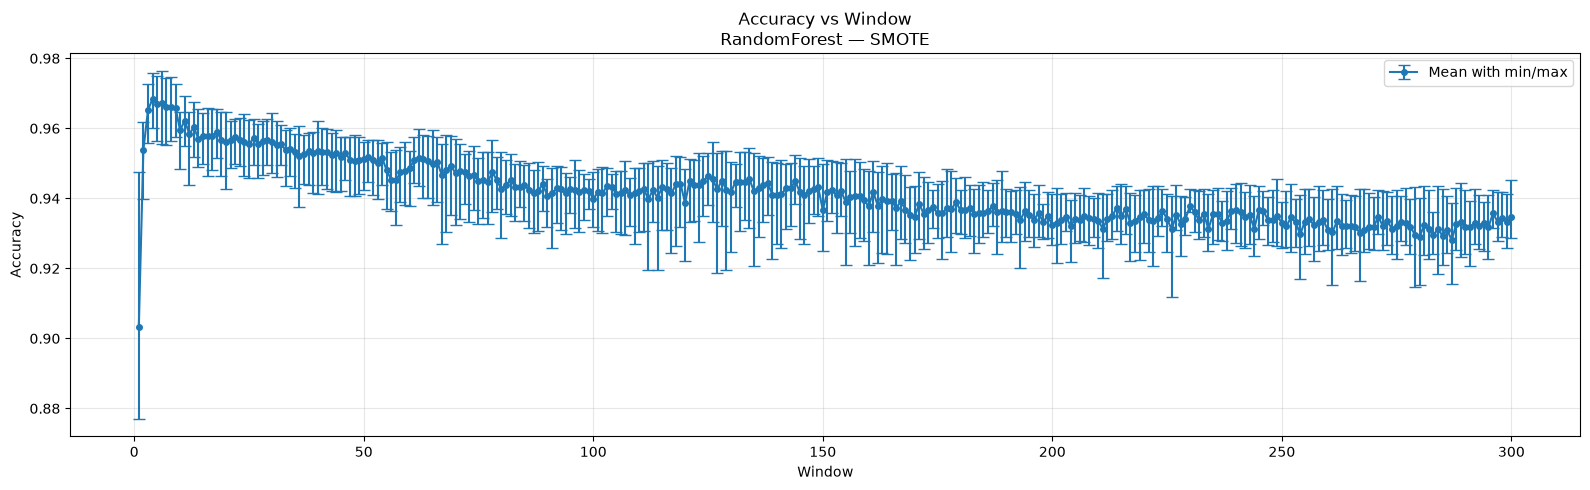

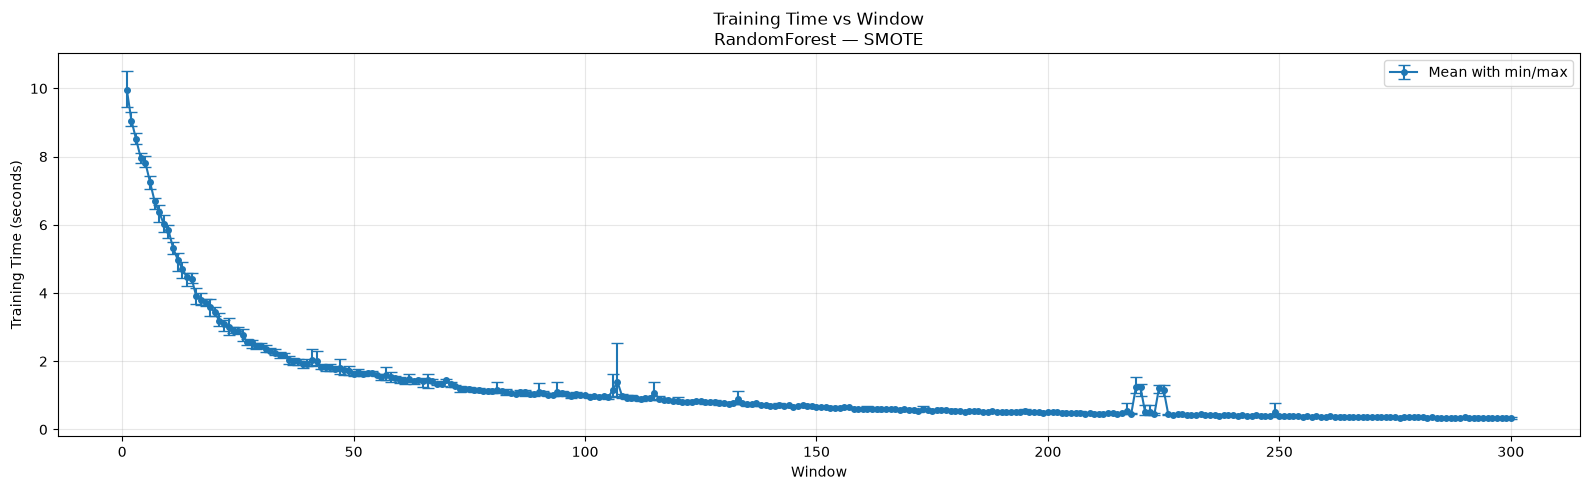

In [29]:
plot_results(combined_df, output_dir="performance-plot")

- Trying out diffferent model and sampling method, window size ranging from 4 to 9 seconds is the best time window given this dataset

## Check for different type of WINDOW calculation
- In this experiment, we will be testing if scrolling window give us better accuracy. The time window range we will be using is from 4 to 9 seconds for both type of window:
    - Fixed window
    - Sliding window

In [23]:
MIN_OPTIMAL_WINDOW, MAX_OPTIMAL_WINDOW = 4, 9

In [28]:
def calculate_features_sliding(
    file_paths: Iterable[str],
    window_size: float,
    step_size: float,
) -> Tuple[pd.DataFrame, float]:
    """
    Calculate packet-count and total-byte features using sliding windows.

    Windows are left-inclusive and right-exclusive:

        [window_start, window_start + window_size)

    For example, window_size=10 and step_size=2 produces:

        [0, 10), [2, 12), [4, 14), ...

    Parameters
    ----------
    file_paths:
        Paths to packet CSV files.

    window_size:
        Duration of each window in seconds.

    step_size:
        Distance between consecutive window starts in seconds.
        For overlapping windows, step_size must be smaller than window_size.

    Returns
    -------
    features:
        DataFrame containing:
        - source_file
        - window
        - window_start
        - window_end
        - eth.src
        - packet_count
        - total_bytes

    elapsed_time:
        Total execution time in seconds.
    """
    if window_size <= 0:
        raise ValueError("window_size must be greater than 0.")

    if step_size <= 0:
        raise ValueError("step_size must be greater than 0.")

    columns = ["frame.time_epoch", "frame.len", "eth.src"]
    all_features = []

    start_time = time.perf_counter()

    for file_path in file_paths:
        df = pd.read_csv(
            file_path,
            usecols=columns,
            dtype={
                "frame.time_epoch": "float64",
                "frame.len": "int32",
                "eth.src": "category",
            },
        )

        if df.empty:
            continue

        capture_start = df["frame.time_epoch"].min()
        capture_end = df["frame.time_epoch"].max()

        # Number of sliding-window start positions.
        number_of_windows = (
            int(np.floor((capture_end - capture_start) / step_size)) + 1
        )

        window_ids = np.arange(number_of_windows, dtype=np.int32)

        # Absolute timestamps used for searching packet positions.
        absolute_window_starts = (
            capture_start + window_ids.astype(np.float64) * step_size
        )
        absolute_window_ends = absolute_window_starts + window_size

        # Relative times are easier to interpret and compare between files.
        relative_window_starts = window_ids.astype(np.float64) * step_size
        relative_window_ends = relative_window_starts + window_size

        for mac, device_df in df.groupby(
            "eth.src",
            sort=False,
            observed=True,
        ):
            # searchsorted requires sorted timestamps.
            device_df = device_df.sort_values(
                "frame.time_epoch",
                kind="mergesort",
            )

            packet_times = device_df["frame.time_epoch"].to_numpy()
            packet_lengths = device_df["frame.len"].to_numpy(
                dtype=np.int64,
            )

            # Locate the packet range belonging to each window.
            left_indices = np.searchsorted(
                packet_times,
                absolute_window_starts,
                side="left",
            )

            right_indices = np.searchsorted(
                packet_times,
                absolute_window_ends,
                side="left",
            )

            packet_counts = right_indices - left_indices

            # Prefix sums allow total bytes to be calculated in O(1)
            # for each window after one cumulative-sum pass.
            cumulative_bytes = np.empty(
                len(packet_lengths) + 1,
                dtype=np.int64,
            )
            cumulative_bytes[0] = 0

            np.cumsum(
                packet_lengths,
                dtype=np.int64,
                out=cumulative_bytes[1:],
            )

            total_bytes = (
                cumulative_bytes[right_indices]
                - cumulative_bytes[left_indices]
            )

            # Preserve the original behavior: do not produce rows for
            # device-window combinations containing no packets.
            non_empty = packet_counts > 0

            if not np.any(non_empty):
                continue

            device_features = pd.DataFrame(
                {
                    "source_file": Path(file_path).name,
                    "window": window_ids[non_empty],
                    "window_start": relative_window_starts[non_empty],
                    "window_end": relative_window_ends[non_empty],
                    "eth.src": mac,
                    "packet_count": packet_counts[non_empty].astype(
                        np.int32
                    ),
                    "total_bytes": total_bytes[non_empty],
                }
            )

            all_features.append(device_features)

    if all_features:
        features = pd.concat(all_features, ignore_index=True)
    else:
        features = pd.DataFrame(
            columns=[
                "source_file",
                "window",
                "window_start",
                "window_end",
                "eth.src",
                "packet_count",
                "total_bytes",
            ]
        )

    elapsed_time = time.perf_counter() - start_time
    print(f"WINDOW: {window} - Computed {len(features):,} samples")

    return features, elapsed_time

In [25]:
fixed_window_metrics = {}
feature_calculate_metric_2 = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(MIN_OPTIMAL_WINDOW, MAX_OPTIMAL_WINDOW + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features(csv_files_1, window)
    feature_calculate_metric_2[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    fixed_window_metrics[window] = experiment_results
    print(f"------------------------------------------")


------------WINDOW: 4-------------
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=SMOTE, scaler=StandardScaler
------------------------------------------
------------WINDOW: 5-------------
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, s

In [26]:
SLIDING_STEP = 2 # 2 seconds

In [29]:
sliding_window_metrics = {}
sliding_feature_calculate_metric = {}
training_features = ["packet_count", "total_bytes"]
label = "is_iot_device"
for window in range(MIN_OPTIMAL_WINDOW, MAX_OPTIMAL_WINDOW + 1):
    print(f"------------WINDOW: {window}-------------")
    features, time_taken = calculate_features_sliding(csv_files_1, window, SLIDING_STEP)
    sliding_feature_calculate_metric[window] = time_taken
    labeled_dataset = label_features(features, device_dict_1)
    X, y = labeled_dataset[training_features], labeled_dataset[label]
    experiment_results = training_and_evaluation(X, y)
    sliding_window_metrics[window] = experiment_results
    print(f"------------------------------------------")


------------WINDOW: 4-------------
WINDOW: 4 - Computed 5,498,763 samples
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=SMOTE, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=SMOTE, scaler=StandardScaler
------------------------------------------
------------WINDOW: 5-------------
WINDOW: 5 - Computed 6,166,654 samples
Training and evaluating with:
Features: ['packet_count', 'total_bytes']
Label: [0 1]
	Start KStratifiedKFold (k=5) for: model=DecisionTree, sample_method=RandomUnderSampler, scaler=StandardScaler
	Start KStratifiedKFold (k=5) for: model=RandomForest, sample_method=RandomUnderSampler, scaler=StandardScaler

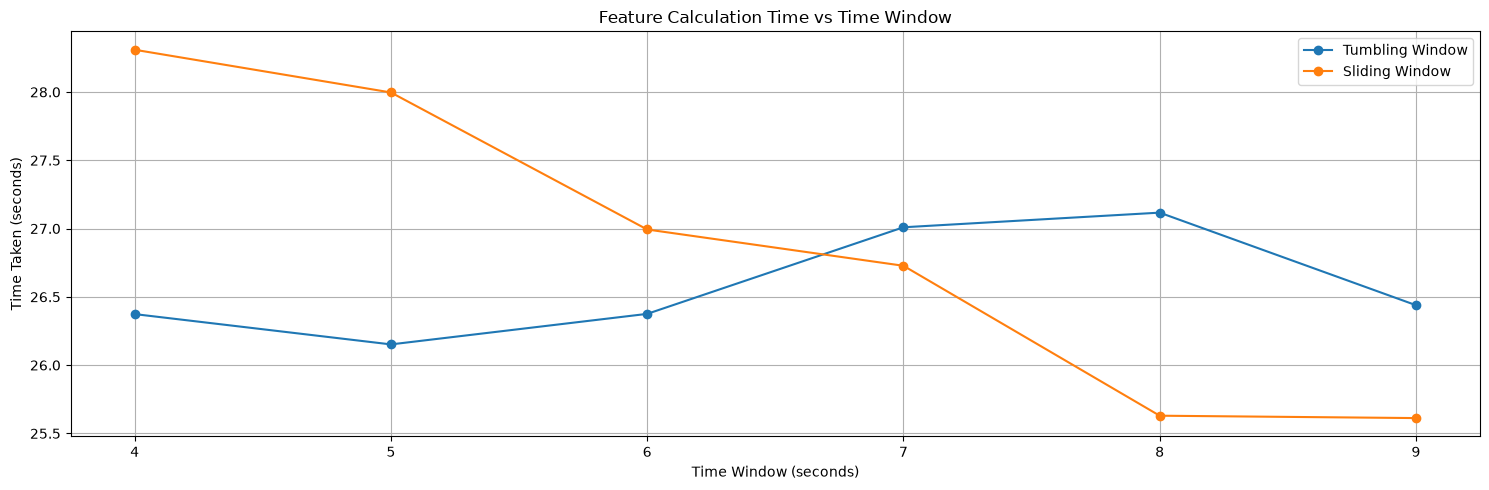

In [30]:
# Tumbling-window metrics
tumbling_x = sorted(feature_calculate_metric_2.keys())
tumbling_y = [
    feature_calculate_metric_2[window]
    for window in tumbling_x
]

# Sliding-window metrics
sliding_x = sorted(sliding_feature_calculate_metric.keys())
sliding_y = [
    sliding_feature_calculate_metric[window]
    for window in sliding_x
]

plt.figure(figsize=(15, 5))

plt.plot(
    tumbling_x,
    tumbling_y,
    marker="o",
    label="Tumbling Window",
)

plt.plot(
    sliding_x,
    sliding_y,
    marker="o",
    label="Sliding Window",
)

plt.title("Feature Calculation Time vs Time Window")
plt.xlabel("Time Window (seconds)")
plt.ylabel("Time Taken (seconds)")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [36]:
def plot_diff_window_results(
    tumbling_results: pd.DataFrame,
    sliding_results: pd.DataFrame,
    output_dir: str = "result_plots",
) -> None:
    """
    Compare tumbling-window and sliding-window results.

    For every (model, sample_method) pair, generate:
      1. Average accuracy by window, with min/max error bars
      2. Average training time by window, with min/max error bars

    Each plot contains separate lines for:
      - Tumbling Window
      - Sliding Window
    """
    required_columns = {
        "model",
        "sample_method",
        "window",
        "accuracy",
        "train_time",
    }

    # Validate both DataFrames.
    for dataframe_name, dataframe in [
        ("tumbling_results", tumbling_results),
        ("sliding_results", sliding_results),
    ]:
        missing = required_columns - set(dataframe.columns)

        if missing:
            raise ValueError(
                f"{dataframe_name} is missing columns: "
                f"{sorted(missing)}"
            )

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    output_path = Path(f"{output_dir}-{timestamp}")
    output_path.mkdir(parents=True, exist_ok=True)

    # Add the window method so the two datasets can be distinguished.
    tumbling_df = tumbling_results.copy()
    tumbling_df["window_type"] = "Tumbling Window"

    sliding_df = sliding_results.copy()
    sliding_df["window_type"] = "Sliding Window"

    # Combine both experiment result sets.
    df = pd.concat(
        [tumbling_df, sliding_df],
        ignore_index=True,
    )

    # Ensure metric columns are numeric.
    numeric_columns = [
        "window",
        "accuracy",
        "train_time",
    ]

    for column in numeric_columns:
        df[column] = pd.to_numeric(
            df[column],
            errors="coerce",
        )

    df = df.dropna(
        subset=[
            "window_type",
            "model",
            "sample_method",
            "window",
            "accuracy",
            "train_time",
        ]
    )

    # Calculate mean, minimum, and maximum for each configuration.
    grouped = (
        df.groupby(
            [
                "window_type",
                "model",
                "sample_method",
                "window",
            ],
            observed=True,
            sort=True,
        )
        .agg(
            accuracy_mean=("accuracy", "mean"),
            accuracy_min=("accuracy", "min"),
            accuracy_max=("accuracy", "max"),
            train_time_mean=("train_time", "mean"),
            train_time_min=("train_time", "min"),
            train_time_max=("train_time", "max"),
        )
        .reset_index()
    )

    # Generate one pair of plots for every model and sampling method.
    for (model, sample_method), pair_df in grouped.groupby(
        ["model", "sample_method"],
        observed=True,
        sort=False,
    ):
        safe_name = re.sub(
            r"[^A-Za-z0-9_-]+",
            "_",
            f"{model}_{sample_method}",
        )

        # -------------------------------------------------
        # Accuracy plot
        # -------------------------------------------------
        plt.figure(figsize=(16, 5))

        for window_type, window_df in pair_df.groupby(
            "window_type",
            observed=True,
            sort=False,
        ):
            window_df = window_df.sort_values("window")
            mean = window_df["accuracy_mean"]

            plt.errorbar(
                window_df["window"],
                mean,
                yerr=[
                    mean - window_df["accuracy_min"],
                    window_df["accuracy_max"] - mean,
                ],
                marker="o",
                markersize=4,
                linewidth=1.5,
                capsize=4,
                label=window_type,
            )

        plt.title(
            f"Accuracy vs Window\n"
            f"{model} — {sample_method}"
        )
        plt.xlabel("Window Size (seconds)")
        plt.ylabel("Accuracy")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_accuracy.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

        # -------------------------------------------------
        # Training-time plot
        # -------------------------------------------------
        plt.figure(figsize=(16, 5))

        for window_type, window_df in pair_df.groupby(
            "window_type",
            observed=True,
            sort=False,
        ):
            window_df = window_df.sort_values("window")
            mean = window_df["train_time_mean"]

            plt.errorbar(
                window_df["window"],
                mean,
                yerr=[
                    mean - window_df["train_time_min"],
                    window_df["train_time_max"] - mean,
                ],
                marker="o",
                markersize=4,
                linewidth=1.5,
                capsize=4,
                label=window_type,
            )

        plt.title(
            f"Training Time vs Window\n"
            f"{model} — {sample_method}"
        )
        plt.xlabel("Window Size (seconds)")
        plt.ylabel("Training Time (seconds)")
        plt.grid(alpha=0.3)
        plt.legend()
        plt.tight_layout()

        plt.savefig(
            output_path / f"{safe_name}_train_time.png",
            dpi=300,
            bbox_inches="tight",
        )

        plt.show()
        plt.close()

    print(f"Plots saved to: {output_path.resolve()}")

In [ ]:
tumbling_metric_copy = deepcopy(fixed_window_metrics)
tumbling_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in tumbling_metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"optimal_tumbling_window_{timestamp}.csv"

tumbling_df.to_csv(filename, index=False)

In [34]:
tumbling_metric_copy = deepcopy(fixed_window_metrics)
tumbling_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in tumbling_metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"optimal_tumbling_window_{timestamp}.csv"

tumbling_df.to_csv(filename, index=False)

In [35]:

sliding_metric_copy = deepcopy(sliding_window_metrics)
sliding_df = pd.concat(
    [
        df.assign(window=window)
        for window, df in sliding_metric_copy.items()
    ],
    ignore_index=True,
)
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
filename = f"optimal_sliding_window_{timestamp}.csv"

sliding_df.to_csv(filename, index=False)

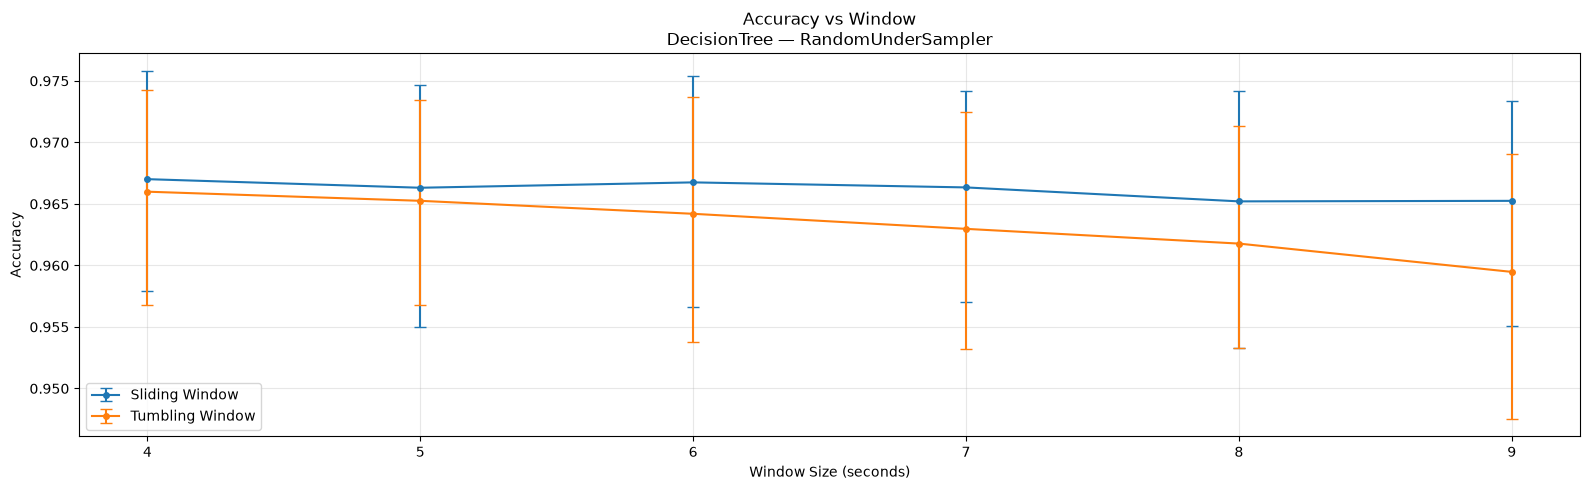

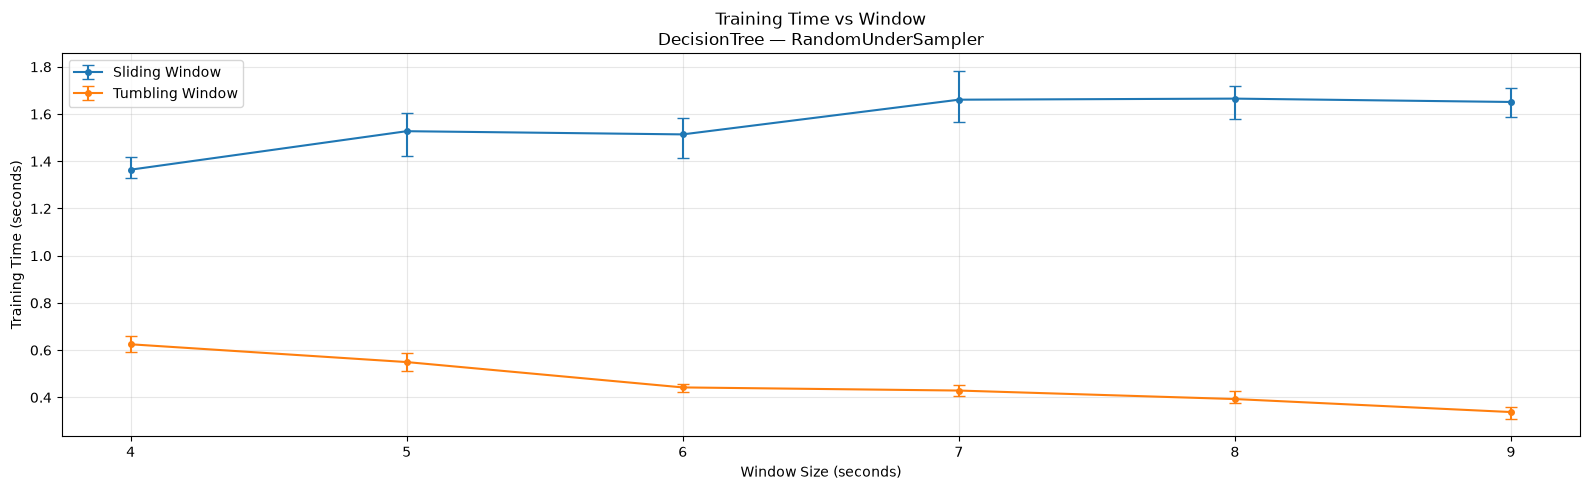

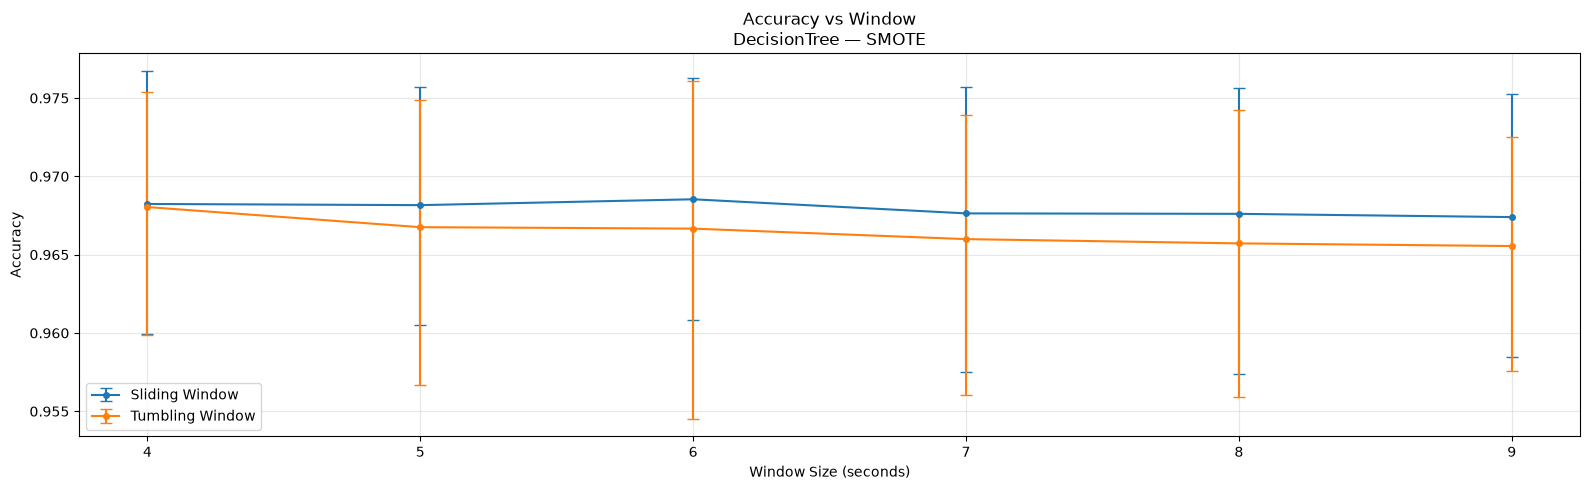

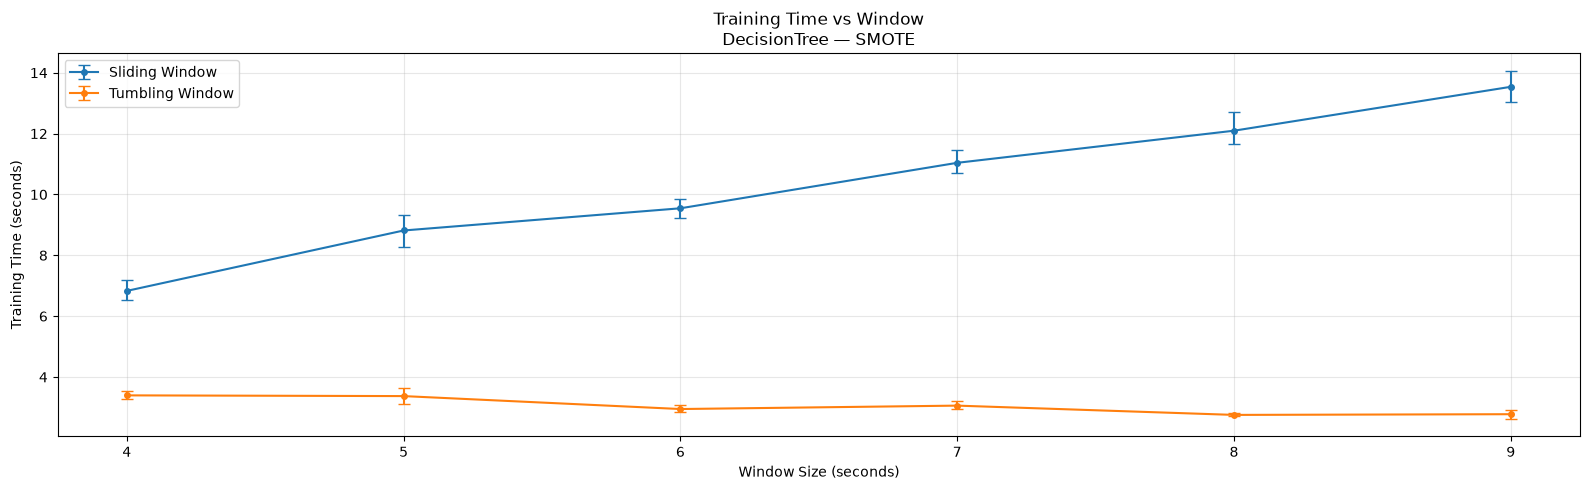

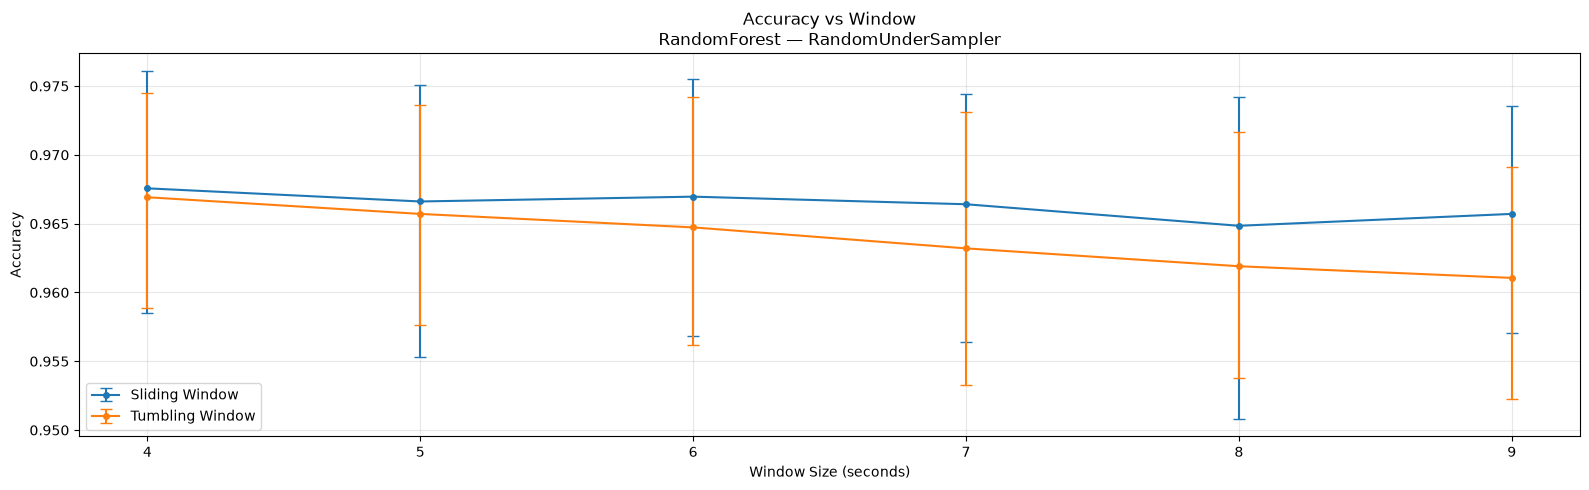

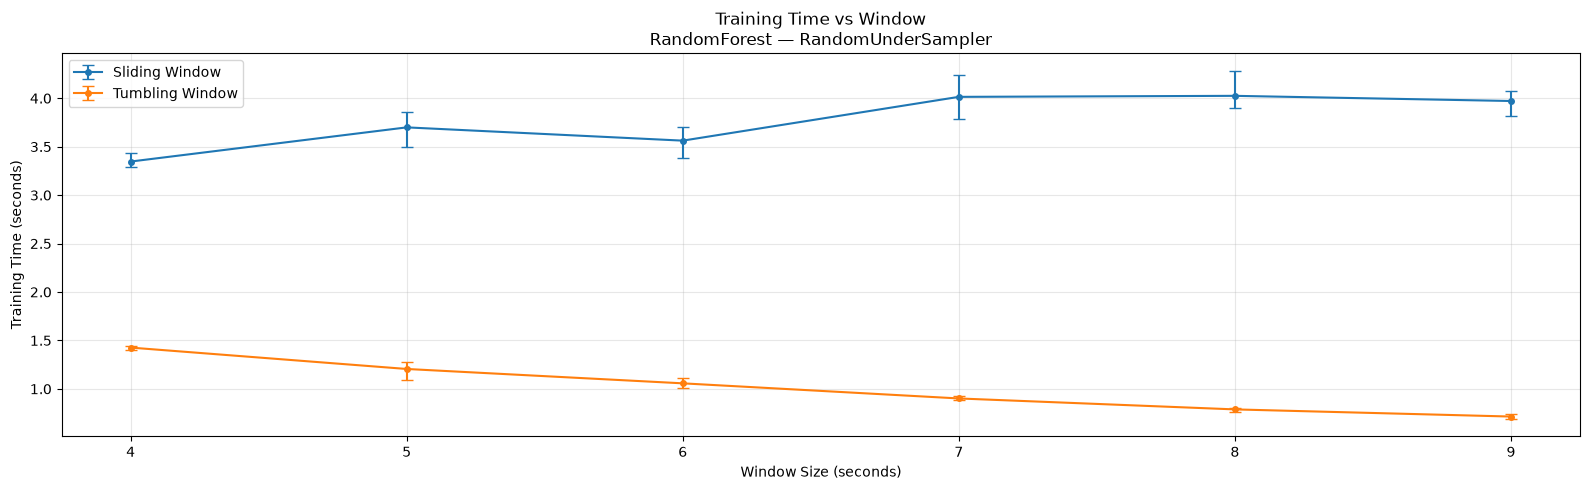

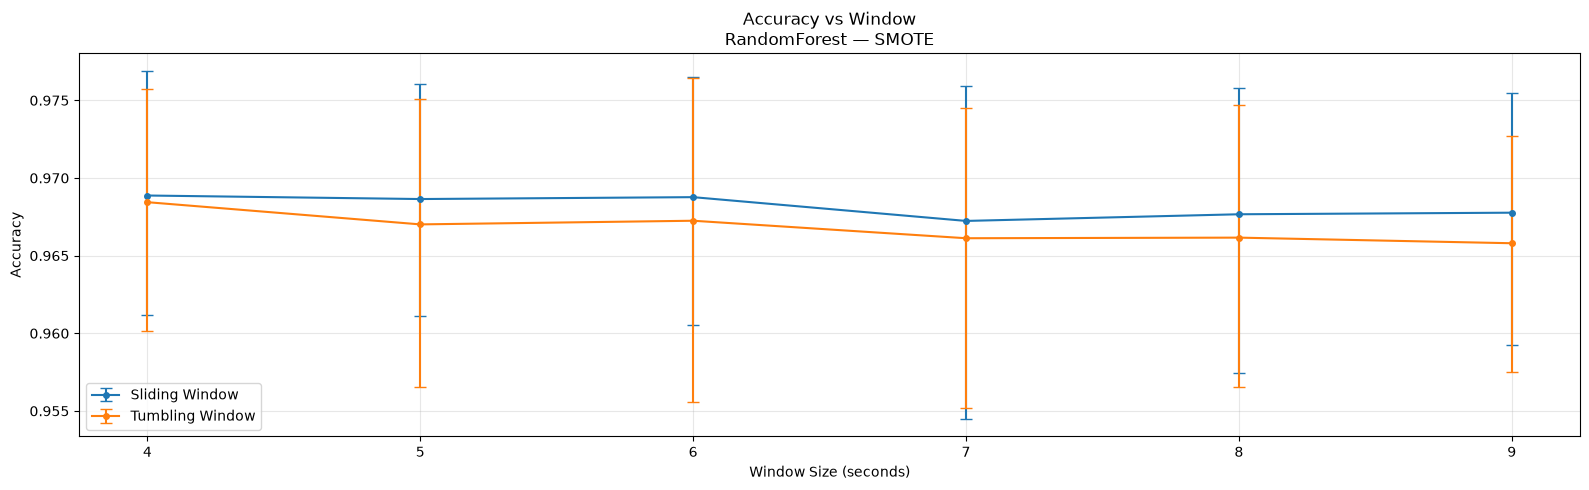

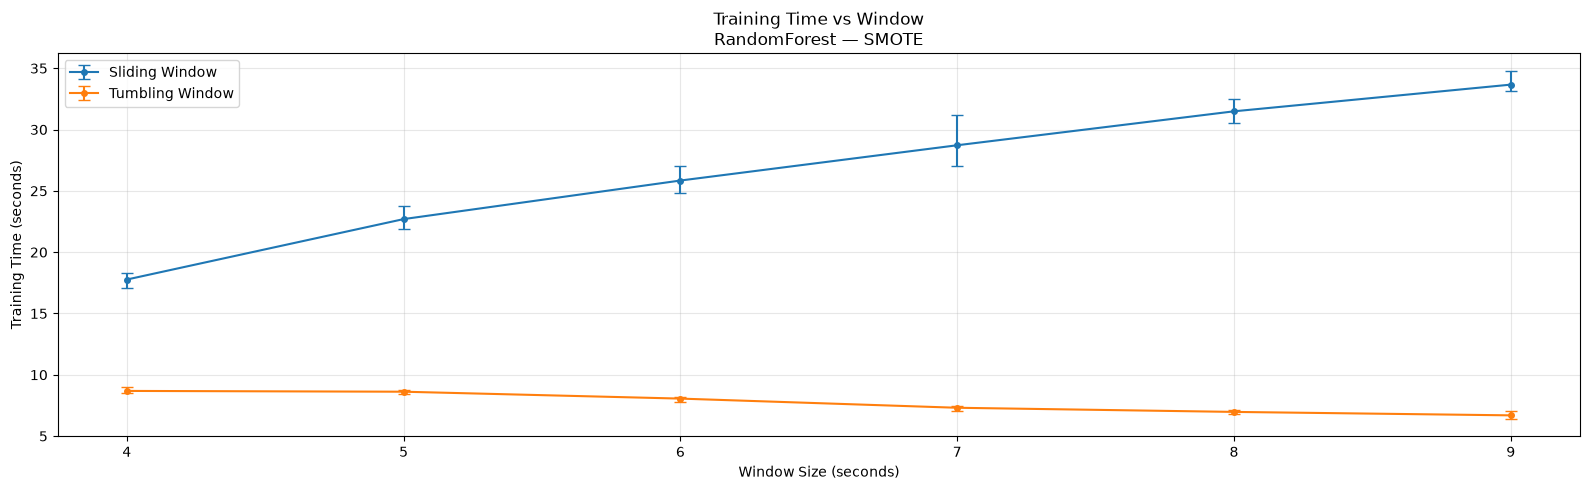

Plots saved to: /Users/duongtuanhoang/simulated-desktop/learning/umsl-cybersecurity/summer2026/research-job/experiment/working/phase-1/tumbling_vs_sliding-20260720_173414


In [37]:
plot_diff_window_results(tumbling_df, sliding_df, output_dir="tumbling_vs_sliding")

## Verify the accuracy in the practical setting

In [5]:
csv_files_2 = [f"{INPUT_2}/{f.name}" for f in sorted(Path(INPUT_2).iterdir()) if f.is_file() and f.suffix == ".csv"]
for file in csv_files_2:
    print(file)

../../../dataset/processed-data/input-data/dataset2/arlo-hub-01.csv
../../../dataset/processed-data/input-data/dataset2/august-hub-01.csv
../../../dataset/processed-data/input-data/dataset2/blink-cam-01.csv
../../../dataset/processed-data/input-data/dataset2/blink-cam-02.csv
../../../dataset/processed-data/input-data/dataset2/blink-cam-03.csv
../../../dataset/processed-data/input-data/dataset2/blink-hub-01.csv
../../../dataset/processed-data/input-data/dataset2/geeni-awarecam-1.csv
../../../dataset/processed-data/input-data/dataset2/geeni-awarecam-2.csv
../../../dataset/processed-data/input-data/dataset2/geeni-cam-01.csv
../../../dataset/processed-data/input-data/dataset2/geeni-cam-03.csv
../../../dataset/processed-data/input-data/dataset2/geeni-doorbell-01.csv
../../../dataset/processed-data/input-data/dataset2/geeni-doorbell-02.csv
../../../dataset/processed-data/input-data/dataset2/hub-02.csv
../../../dataset/processed-data/input-data/dataset2/hue-hub-01.csv
../../../dataset/process